In [2]:
import sys
import os
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from benchannot.prokaryotic.id_matching import (
    clean_id, parse_gbk_identifiers, parse_eggnog_candidates,
    safe_uniprot_mapping, smart_eggnog_mapping, get_best_mapping,
    calculate_id_metrics
)
from benchannot.paths import (
    pgap_annotation_path,
    project_paths,
    validate_required_inputs,
)

In [3]:
ORGANISMS = {
    "bacillus_subtilis": "B. subtilis",
    "escherichia_coli": "E. coli"
}

ORGANISM_TAXIDS = {
    "escherichia_coli": "562",
    "bacillus_subtilis": "1423",
}

TOOLS_TO_EVALUATE = ['Prokka', 'Bakta', 'PGAP', 'eggNOG']

DATASET = "reproduced"  # "origin" or "reproduced"
PATHS = project_paths(DATASET)

OUTPUT_DIR = PATHS.analysis_output / "prokaryotic"
PROKARYOTE_TOOLS_DIR = PATHS.prokaryote_tools
GENOME_PROKARYOTE_DIR = PATHS.genome_prokaryote

print(f"Dataset: {DATASET}")
print(f"Tool inputs: {PROKARYOTE_TOOLS_DIR}")
print(f"Analysis inputs: {OUTPUT_DIR}")

Dataset: reproduced
Tool inputs: /var/locally-mounted/cauim/marymardegan/documents_marymardegan/analysis_benchannot/data/reproduced/prokaryote_output_tools
Analysis inputs: /var/locally-mounted/cauim/marymardegan/documents_marymardegan/analysis_benchannot/analysis_benchannot/2_run/output/reproduced/prokaryotic


## 1. Load Data & Parse Annotation Files

For each organism, load the concordant CDS set and parse the Reference, Prokka, Bakta, PGAP, and eggNOG annotation files. All sources are merged on `orf_id` to produce a unified working DataFrame.

In [4]:
id_matching_inputs = {}
for organism in ORGANISMS:
    id_matching_inputs.update(
        {
            f"{organism} concordant CDS ({DATASET})": (
                OUTPUT_DIR / f"{organism}_concordant_CDS.csv"
            ),
            f"{organism} NCBI RefSeq reference GBFF": (
                GENOME_PROKARYOTE_DIR / f"{organism}.gbff"
            ),
            f"{organism} Prokka GBK ({DATASET})": (
                PROKARYOTE_TOOLS_DIR / "prokka" / f"{organism}.gbk"
            ),
            f"{organism} Bakta GBFF ({DATASET})": (
                PROKARYOTE_TOOLS_DIR / "bakta" / f"{organism}.gbff"
            ),
            f"{organism} PGAP GBK ({DATASET})": pgap_annotation_path(
                PATHS, organism, "gbk"
            ),
            f"{organism} eggNOG decorated GFF ({DATASET})": (
                PROKARYOTE_TOOLS_DIR
                / "eggnog"
                / f"{organism}.emapper.decorated.gff"
            ),
        }
    )

validate_required_inputs(
    id_matching_inputs,
    context=f"prokaryotic identifier-source parsing ({DATASET})",
)

In [5]:
parsed_data = {}

for org_id, org_name in ORGANISMS.items():
    CONCORDANT_CSV = OUTPUT_DIR / f"{org_id}_concordant_CDS.csv"
    print(f"\n{'='*43}")
    print(f"  Loading: {org_name}")
    print(f"{'='*43}\n")

    if not os.path.exists(CONCORDANT_CSV):
        print(f"Skipping {org_id}.")
        continue

    df_func = pd.read_csv(CONCORDANT_CSV)
    df_func.drop(
        columns=[c for c in df_func.columns if 'product_' in c or 'Start' in c or 'End' in c or 'Strand' in c],
        inplace=True, errors='ignore'
    )

    df_gbff = parse_gbk_identifiers(GENOME_PROKARYOTE_DIR / f"{org_id}.gbff", "Reference")
    df_prokka = parse_gbk_identifiers(PROKARYOTE_TOOLS_DIR / "prokka" / f"{org_id}.gbk", "Prokka")
    df_bakta = parse_gbk_identifiers(PROKARYOTE_TOOLS_DIR / "bakta" / f"{org_id}.gbff", "Bakta")
    df_pgap = parse_gbk_identifiers(
        pgap_annotation_path(PATHS, org_id, "gbk"), "PGAP"
    )

    eggnog_candidates = parse_eggnog_candidates(
        PROKARYOTE_TOOLS_DIR / "eggnog" / f"{org_id}.emapper.decorated.gff"
    )
    df_func["eggNOG_candidates"] = df_func["orf_id"].map(eggnog_candidates)

    for df in [df_gbff, df_prokka, df_bakta, df_pgap]:
        df_func = pd.merge(df_func, df, on='orf_id', how='left')

    df_func = df_func[df_func['Reference_ID'].notna()]
    parsed_data[org_id] = {'name': org_name, 'df_func': df_func}


  Loading: B. subtilis


  Loading: E. coli



## 2. UniProt ID Mapping

Map tool-specific identifiers to UniProtKB accession numbers. PGAP IDs are resolved via the RefSeq_Protein database. eggNOG IDs use a cascade strategy (STRING -> GI -> Gene Name -> EMBL). Bakta and Prokka IDs are already UniProt-compatible after cleaning.

In [6]:
for org_id, org_data in parsed_data.items():
    df_func = org_data['df_func']
    org_name = org_data['name']

    print(f"\n  UniProt Mapping: {org_name}")
    pgap_raw = df_func['PGAP_ID'].dropna().apply(clean_id).tolist()

    eggnog_raw = []
    for cands in df_func["eggNOG_candidates"].dropna():
        eggnog_raw.extend(cands)
    eggnog_raw = list(set(eggnog_raw))

    df_pgap_uniprot = safe_uniprot_mapping(pgap_raw, from_db='RefSeq_Protein', to_db='UniProtKB')
    df_eggnog_uniprot = smart_eggnog_mapping(eggnog_raw, tax_id=ORGANISM_TAXIDS[org_id])

    dict_pgap = dict(zip(df_pgap_uniprot['From'], df_pgap_uniprot['To'])) if not df_pgap_uniprot.empty else {}
    dict_eggnog = dict(zip(df_eggnog_uniprot['From'], df_eggnog_uniprot['To'])) if not df_eggnog_uniprot.empty else {}

    df_func['UniProt_PGAP'] = df_func['PGAP_ID'].apply(lambda x: dict_pgap.get(clean_id(x), np.nan))
    df_func['UniProt_Bakta'] = df_func['Bakta_ID'].apply(clean_id)
    df_func['UniProt_Prokka'] = df_func['Prokka_ID'].apply(clean_id)
    df_func['UniProt_Reference'] = df_func['Reference_ID'].apply(clean_id)
    df_func['UniProt_eggNOG'] = df_func['eggNOG_candidates'].apply(lambda c: get_best_mapping(c, dict_eggnog))


  UniProt Mapping: B. subtilis
  > Mapping: RefSeq_Protein -> UniProtKB (3705 IDs)...
    -> Success: Mapped 932 IDs via RefSeq_Protein.
  > Mapping: STRING -> UniProtKB (6685 IDs)...
    -> Success: Mapped 3114 IDs via STRING.
  > Mapping: Gene Name -> UniProtKB (3571 IDs)...
    -> Success: Mapped 264 IDs via Gene Name.
  > Mapping: EMBL/GenBank/DDBJ -> UniProtKB (3471 IDs)...
    -> Success: 0 IDs mapped via EMBL/GenBank/DDBJ.

  UniProt Mapping: E. coli
  > Mapping: RefSeq_Protein -> UniProtKB (3768 IDs)...
    -> Success: Mapped 2530 IDs via RefSeq_Protein.
  > Mapping: STRING -> UniProtKB (7420 IDs)...
    -> Success: Mapped 1257 IDs via STRING.
  > Mapping: GI number -> UniProtKB (1166 IDs)...
    -> Success: Mapped 1166 IDs via GI number.
  > Mapping: Gene Name -> UniProtKB (4997 IDs)...
    -> Success: Mapped 1149 IDs via Gene Name.
  > Mapping: EMBL/GenBank/DDBJ -> UniProtKB (4712 IDs)...
    -> Success: Mapped 0 IDs via EMBL/GenBank/DDBJ.


## 3. UniRef100 Clustering & Metrics

Map all UniProt accessions to UniRef100 clusters, then compute the Exact UniProt Match Rate and UniRef100 Cluster Match Rate for each tool against the Reference.

In [7]:
all_metrics = {}

for org_id, org_data in parsed_data.items():
    df_func = org_data['df_func']
    org_name = org_data['name']

    print(f"\n  UniRef100 Clustering: {org_name}")
    all_uniprot = list(set(
        df_func['UniProt_Bakta'].dropna().tolist() + df_func['UniProt_Prokka'].dropna().tolist() + 
        df_func['UniProt_Reference'].dropna().tolist() + df_func['UniProt_PGAP'].dropna().tolist() + 
        df_func['UniProt_eggNOG'].dropna().tolist()
    ))

    df_uniref = safe_uniprot_mapping(all_uniprot, from_db='UniProtKB_AC-ID', to_db='UniRef100')
    dict_uniref = dict(zip(df_uniref['From'], df_uniref['To'])) if not df_uniref.empty else {}

    for tool in ['PGAP', 'eggNOG', 'Bakta', 'Prokka', 'Reference']:
        df_func[f'Cluster_{tool}'] = df_func[f'UniProt_{tool}'].apply(lambda x: dict_uniref.get(x, np.nan))

    df_metrics = calculate_id_metrics(df_func, tools=TOOLS_TO_EVALUATE)
    all_metrics[org_id] = {'name': org_name, 'metrics': df_metrics}

    display(df_metrics.style.background_gradient(cmap='Blues', subset=['Exact UniProt Rate (%)', 'UniRef100 Cluster Rate (%)']))


  UniRef100 Clustering: B. subtilis
  > Mapping: UniProtKB_AC-ID -> UniRef100 (4421 IDs)...
    -> Success: Mapped 421 IDs via UniProtKB_AC-ID.


,Annotation Tool,Exact UniProt Rate (%),UniRef100 Cluster Rate (%),Ref. IDs Available (100%),UniProt Matches (n),Cluster Matches (n)
0,Prokka,44.710000,40.940000,3706,1657,140
1,Bakta,99.430000,99.120000,3706,3685,339
2,PGAP,23.580000,23.980000,3706,874,82
3,eggNOG,84.000000,84.210000,3706,3113,288



  UniRef100 Clustering: E. coli
  > Mapping: UniProtKB_AC-ID -> UniRef100 (5022 IDs)...
    -> Success: Mapped 5022 IDs via UniProtKB_AC-ID.


,Annotation Tool,Exact UniProt Rate (%),UniRef100 Cluster Rate (%),Ref. IDs Available (100%),UniProt Matches (n),Cluster Matches (n)
0,Prokka,74.770000,75.850000,3785,2830,2871
1,Bakta,97.070000,97.570000,3785,3674,3693
2,PGAP,36.040000,46.610000,3785,1364,1764
3,eggNOG,28.110000,34.480000,3785,1064,1305


## 4. Visualization

Bar charts comparing Exact UniProt Match Rate and UniRef100 Cluster Match Rate across all annotation tools for each organism.

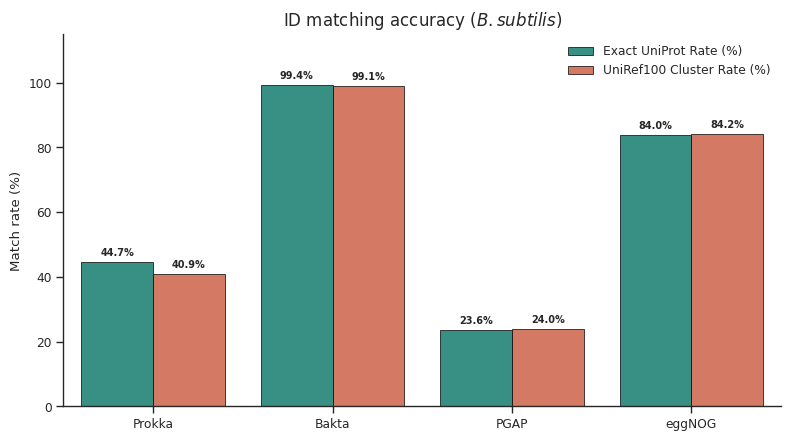

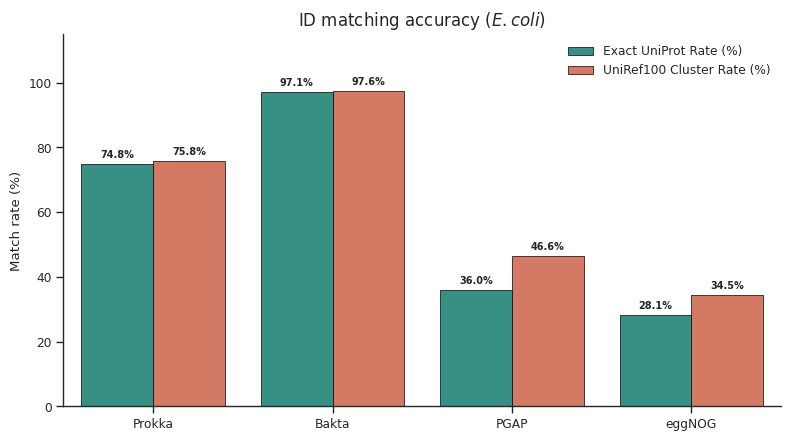

In [8]:
sns.set_theme(style="ticks", context="paper")

for org_id, org_data in all_metrics.items():
    df_metrics = org_data['metrics']
    org_name = org_data['name']

    melted = df_metrics.melt(
        id_vars='Annotation Tool',
        value_vars=['Exact UniProt Rate (%)', 'UniRef100 Cluster Rate (%)'],
        var_name='Metric', value_name='Rate'
    )

    fig, ax = plt.subplots(figsize=(8, 4.5))

    bars = sns.barplot(
        data=melted,
        x="Annotation Tool",
        y="Rate",
        hue="Metric",
        palette=['#2a9d8f', '#e76f51'],
        edgecolor="black",
        linewidth=0.5,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=7, fontweight='bold')

    ax.set_ylim(0, 115)
    ax.set_ylabel("Match rate (%)")
    ax.set_xlabel("")
    ax.set_title(
        f"ID matching accuracy ($\\it{{{org_name}}}$)",
        fontsize=12,
    )

    sns.despine(ax=ax)

    ax.legend(
        title="",
        frameon=False,
        loc="upper right",
    )

    plt.tight_layout()
    plt.show()